# Lab Assignment 10: Multi-Head Attention, Transformer Encoders & Fine-Tuning BERT

**Objective:**
In Lab 8 you built a single attention mechanism inside an LSTM. In Lab 9 you fine-tuned a pre-trained Transformer for translation. In this lab you will **open the black box**: build *scaled dot-product attention* and *multi-head attention* from scratch, assemble them into a mini Transformer encoder, and then compare it with a pre-trained **BERT** model fine-tuned on the same task.

**Task:** Sentiment classification on the **SST-2** dataset (positive / negative movie-review sentences).

**Learning outcomes**
1. Implement scaled dot-product and multi-head attention and verify them against PyTorch.
2. Build a Transformer encoder block (attention + feed-forward + residual + LayerNorm + positional encoding).
3. Understand why BERT (bidirectional, pre-trained encoder) is different from the decoder/LSTM models in previous labs.
4. Fine-tune BERT and evaluate with Accuracy and F1.
5. Visualise and interpret what individual attention heads learn.

| Part | Topic | Points |
|---|---|---|
| 1 | Setup & Data | 10 |
| 2 | Scaled Dot-Product Attention | 15 |
| 3 | Multi-Head Attention + Encoder Block | 25 |
| 4 | Mini-Transformer trained from scratch | 15 |
| 5 | Fine-tuning BERT | 20 |
| 6 | Attention Head Visualisation | 10 |
| 7 | Comparative Analysis & Reflection | 5 |
| | **Total** | **100** |


## Theory Recap

**Scaled dot-product attention** (Lab 8 used an un-scaled version):

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

* `Q` (queries), `K` (keys), `V` (values) are linear projections of the input.
* Dividing by $\sqrt{d_k}$ stops the dot products from growing large, which would push softmax into regions with tiny gradients.

**Multi-head attention** runs `h` attention operations in parallel, each in a lower-dimensional subspace ($d_k = d_{model}/h$), then concatenates and projects the results:

$$\text{MHA}(X)=\text{Concat}(\text{head}_1,\dots,\text{head}_h)W^O$$

Different heads can specialise (e.g. syntax, neighbouring words, rare-word focus).

**BERT** = a stack of Transformer *encoder* blocks, pre-trained with Masked Language Modelling (MLM) and Next-Sentence Prediction (NSP). The `[CLS]` token's final hidden state is used as the sentence representation for classification.

| Model | Direction | Attention type | Pre-trained? |
|---|---|---|---|
| LSTM + Attention (Lab 8) | Left→right encoder (or BiLSTM) | Cross-attention only | No |
| Marian Transformer (Lab 9) | Encoder-decoder | Self + Cross | Yes |
| **BERT (this lab)** | Encoder only, bidirectional | Self-attention | Yes |


## Part 1: Setup and Data (10 points)

### 1.1 Install & import libraries

In [1]:
!pip install -q transformers datasets evaluate accelerate bertviz scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 4.2 MB/s eta 0:00:00


In [2]:
import os, math, time, random, copy
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import transformers
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, DataCollatorWithPadding, pipeline)
from datasets import load_dataset, DatasetDict

transformers.logging.set_verbosity_error()   # hide the (expected) "newly initialized weights" warnings

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

def count_params(model, trainable_only=True):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

results = {}   # every model adds a row here -> comparison table in Part 7

torch 2.11.0+cu130 | transformers 5.18.0
device: cuda | Tesla T4


### 1.2 Load SST-2
Use `load_dataset("glue", "sst2")`. To keep training fast on a Colab T4, use a **subset**: 5,000 training samples and the full validation set (872 samples) as your test set.
Print the dataset structure, 3 random examples, and the class distribution.

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

Subsets used in this lab:
DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 5000
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
})

3 random training examples:
  [positive] mariah carey gives us another peek at some of the magic we saw in glitter here in wisegirls . 
  [positive] does its best 
  [negative] lack contrast , are murky and 

Class distribution:
  train     : negative=2266 (45.3%), positive=2734 (54.7%)
  validation: negative=430 (43.0%), positive=570 

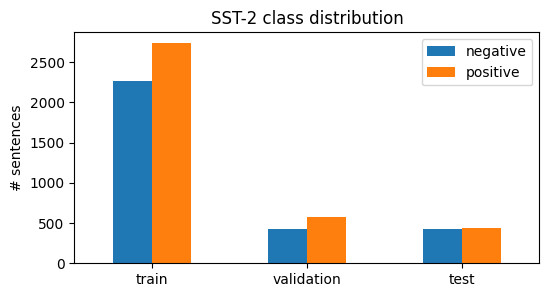

In [3]:
N_TRAIN, N_VAL = 5000, 1000
label_names = ["negative", "positive"]

try:
    sst2 = load_dataset("glue", "sst2")
except Exception:
    sst2 = load_dataset("nyu-mll/glue", "sst2")       # current hub location of GLUE
print(sst2)

# Train: 5,000 sentences sampled from the SST-2 train split.
# Validation: 1,000 *other* train sentences, used for per-epoch monitoring (so the test set is never
#             looked at during training).
# Test: the full official validation split (872 sentences) - the GLUE test split has no public labels.
shuffled = sst2["train"].shuffle(seed=SEED)
raw = DatasetDict({
    "train": shuffled.select(range(N_TRAIN)),
    "validation": shuffled.select(range(N_TRAIN, N_TRAIN + N_VAL)),
    "test": sst2["validation"],
})
print("\nSubsets used in this lab:")
print(raw)

print("\n3 random training examples:")
for i in random.sample(range(N_TRAIN), 3):
    ex = raw["train"][i]
    print(f"  [{label_names[ex['label']]:8s}] {ex['sentence']}")

print("\nClass distribution:")
dist = {}
for split in raw:
    c = Counter(raw[split]["label"])
    dist[split] = [c[0], c[1]]
    print(f"  {split:10s}: " + ", ".join(f"{label_names[k]}={c[k]} ({c[k] / len(raw[split]):.1%})" for k in (0, 1)))

pd.DataFrame(dist, index=label_names).T.plot.bar(rot=0, figsize=(6, 3), title="SST-2 class distribution")
plt.ylabel("# sentences")
plt.show()

### 1.3 Tokenize
Load the `bert-base-uncased` tokenizer. Tokenize with `truncation=True`, `max_length=64`, and pad dynamically (use `DataCollatorWithPadding`).
Print one sentence together with its `input_ids`, the decoded tokens (`convert_ids_to_tokens`) and the `attention_mask`. **Explain in a markdown cell:** what are `[CLS]`, `[SEP]` and `##` word-pieces?

In [4]:
MODEL_NAME = "bert-base-uncased"
MAX_LEN = 64
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    # no padding here: DataCollatorWithPadding pads each batch to its own longest sentence
    return tokenizer(batch["sentence"], truncation=True, max_length=MAX_LEN)

tokenized = raw.map(tokenize_fn, batched=True, remove_columns=["sentence", "idx"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenized)

# pick a training sentence that contains word-pieces so that [CLS], [SEP] and ## are all visible
example = next(s for s in raw["train"]["sentence"]
               if any(t.startswith("##") for t in tokenizer.tokenize(s)))
enc = tokenizer(example, truncation=True, max_length=MAX_LEN)
print("\nSentence      :", example)
print("input_ids     :", enc["input_ids"])
print("tokens        :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("attention_mask:", enc["attention_mask"])

# dynamic padding: sentences of different lengths in one batch
batch = data_collator([tokenized["train"][i] for i in range(3)])
print("\nDynamically padded batch:", {k: tuple(v.shape) for k, v in batch.items()})
print("attention_mask (0 = padding):\n", batch["attention_mask"])

lengths = np.array([len(x) for x in tokenized["train"]["input_ids"]])
print(f"\nTokens per sentence: mean={lengths.mean():.1f}, max={lengths.max()}, "
      f"truncated at {MAX_LEN}: {(lengths == MAX_LEN).mean():.2%}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 872
    })
})

Sentence      : be fruitful 
input_ids     : [101, 2022, 5909, 3993, 102]
tokens        : ['[CLS]', 'be', 'fruit', '##ful', '[SEP]']
attention_mask: [1, 1, 1, 1, 1]

Dynamically padded batch: {'input_ids': (3, 17), 'token_type_ids': (3, 17), 'attention_mask': (3, 17), 'labels': (3,)}
attention_mask (0 = padding):
 tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

Tokens per sentence: mean=13.3, max=59, truncated at 64: 0.00%


**`[CLS]`, `[SEP]` and `##` word-pieces** (see the example above: `be fruitful` → `[CLS] be fruit ##ful [SEP]` = ids `101 … 102`)

* **`[CLS]`** ("classification", id 101) is prepended to every input. Through self-attention it can gather information from every other token, and during pre-training its final hidden state was trained for the Next-Sentence-Prediction task. That's why its last-layer vector (passed through BERT's *pooler*) is used as the sentence representation that `AutoModelForSequenceClassification` feeds to its linear classifier.
* **`[SEP]`** ("separator", id 102) marks the end of a segment. For sentence pairs (NSP, QA, NLI) the input is `[CLS] A [SEP] B [SEP]`, and `token_type_ids` tell the model which segment each token belongs to. For a single sentence like SST-2 it is just `[CLS] sentence [SEP]`.
* **`##` word-pieces**: BERT uses a WordPiece vocabulary of 30,522 sub-words. A word that is not in the vocabulary is split into known pieces, and `##` marks a piece that **continues the previous token without a space**. Here *fruitful* is not in the vocabulary, so it becomes `fruit` + `##ful`. Almost any word can therefore be represented without `[UNK]`, and rare words share sub-word meaning with common ones (`##ful` also appears in *helpful*, *painful*, …).
* **`attention_mask`**: 1 = real token, 0 = padding. In the dynamically padded batch above, the batch is padded to the longest sentence (17 tokens) and the two short sentences get 0s for their 12 padding positions, so attention ignores those positions. SST-2 sentences are short (mean 13.3 tokens, max 59), so `max_length=64` truncates nothing.

## Part 2: Scaled Dot-Product Attention from Scratch (15 points)

### 2.1 Implement the function
Write `scaled_dot_product_attention(Q, K, V, mask=None)` that returns `(output, attention_weights)`.

Requirements:
* Input shapes: `(batch, heads, seq_len, d_k)`
* Scale by `sqrt(d_k)`
* If `mask` is given (1 = keep, 0 = padding), set masked scores to a very large negative number **before** softmax
* Do **not** use `nn.MultiheadAttention` or `F.scaled_dot_product_attention` in your implementation

In [5]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q, K, V : (batch, heads, seq_len, d_k)
    mask    : broadcastable to (batch, heads, seq_len_q, seq_len_k); 1 = keep, 0 = padding
    returns : output (batch, heads, seq_len_q, d_k), attention_weights (batch, heads, seq_len_q, seq_len_k)
    """
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)            # (B, h, T_q, T_k)
    if mask is not None:
        # very large negative number BEFORE softmax -> exp(...) = 0 for padded keys
        # (finfo.min instead of a hard-coded -1e9 so it also works in fp16)
        scores = scores.masked_fill(mask == 0, torch.finfo(scores.dtype).min)
    attention_weights = torch.softmax(scores, dim=-1)             # normalise over the keys
    output = attention_weights @ V                                # weighted average of the values
    return output, attention_weights

### 2.2 Verify
Create random `Q, K, V` and compare your output with `torch.nn.functional.scaled_dot_product_attention` using `torch.allclose`. Also check that every row of the weights sums to 1 and that padded positions receive ~0 weight.

In [6]:
set_seed()
B, h, T, d_k = 2, 4, 6, 16
Q, K, V = torch.randn(B, h, T, d_k), torch.randn(B, h, T, d_k), torch.randn(B, h, T, d_k)

# padding mask (1 = real token, 0 = padding): the 2nd sequence has 2 padded positions at the end
pad = torch.tensor([[1, 1, 1, 1, 1, 1],
                    [1, 1, 1, 1, 0, 0]])
mask = pad[:, None, None, :]                                       # (B, 1, 1, T): broadcasts over heads & queries

out, w = scaled_dot_product_attention(Q, K, V, mask)
ref = F.scaled_dot_product_attention(Q, K, V, attn_mask=mask.bool())   # bool mask: True = may attend
out_nm, _ = scaled_dot_product_attention(Q, K, V)
ref_nm = F.scaled_dot_product_attention(Q, K, V)

print("output shape:", tuple(out.shape), "| weights shape:", tuple(w.shape))
print("matches F.scaled_dot_product_attention (no mask)  :", torch.allclose(out_nm, ref_nm, atol=1e-5))
print("matches F.scaled_dot_product_attention (with mask):", torch.allclose(out, ref, atol=1e-5))
print("max abs difference                                :", (out - ref).abs().max().item())
print("every row of the weights sums to 1                :", torch.allclose(w.sum(-1), torch.ones(B, h, T)))
print("largest weight on a padded key                    :", w[1, :, :, 4:].max().item())
print("\nSequence 2, head 1 attention weights (last 2 columns = padding):")
print(w[1, 0].numpy().round(3))

output shape: (2, 4, 6, 16) | weights shape: (2, 4, 6, 6)
matches F.scaled_dot_product_attention (no mask)  : True
matches F.scaled_dot_product_attention (with mask): True
max abs difference                                : 2.384185791015625e-07
every row of the weights sums to 1                : True
largest weight on a padded key                    : 0.0

Sequence 2, head 1 attention weights (last 2 columns = padding):
[[0.404 0.118 0.256 0.222 0.    0.   ]
 [0.289 0.262 0.155 0.294 0.    0.   ]
 [0.398 0.11  0.408 0.084 0.    0.   ]
 [0.365 0.172 0.099 0.364 0.    0.   ]
 [0.183 0.424 0.187 0.206 0.    0.   ]
 [0.439 0.006 0.524 0.031 0.    0.   ]]


### 2.3 Short question
Compare this with the attention you wrote in **Lab 8** (Bahdanau / dot-product). In 3-4 lines: what is the difference between *additive* and *scaled dot-product* attention, and why does the scaling factor matter? *(Hint: try d_k = 512 with and without scaling and print the std of the scores and the max softmax weight.)*

  d_k |           score std |   avg max softmax w |  avg |grad| at scores
      |       raw    scaled |       raw    scaled |        raw     scaled
----------------------------------------------------------------------------
    4 |      2.00      1.00 |     0.452     0.271 |   7.03e-02   7.44e-02
   64 |      6.59      0.82 |     0.825     0.260 |   1.99e-02   7.30e-02
  512 |     24.27      1.07 |     0.996     0.377 |   1.12e-03   7.78e-02


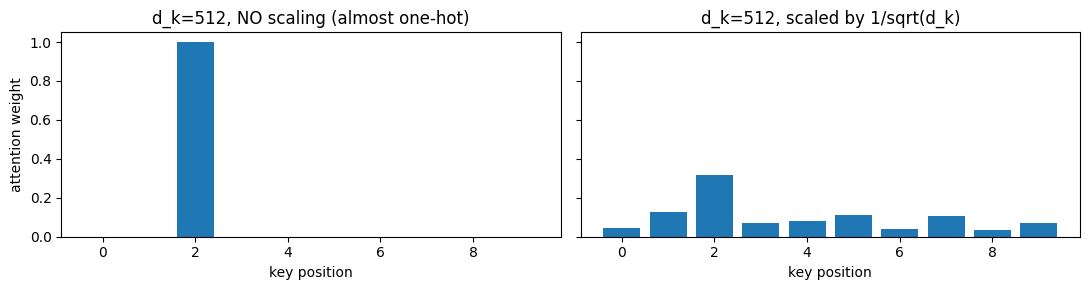

In [7]:
set_seed()
T = 10
print(f"{'d_k':>5} | {'score std':>19} | {'avg max softmax w':>19} | {'avg |grad| at scores':>21}")
print(f"{'':>5} | {'raw':>9} {'scaled':>9} | {'raw':>9} {'scaled':>9} | {'raw':>10} {'scaled':>10}")
print("-" * 76)
for d_k in [4, 64, 512]:
    q, k = torch.randn(1, 1, T, d_k), torch.randn(1, 1, T, d_k)
    upstream = torch.randn(1, 1, T, T)                  # same random upstream gradient for both versions
    raw_scores = q @ k.transpose(-2, -1)
    stats = []
    for s in (raw_scores, raw_scores / math.sqrt(d_k)):
        s = s.clone().requires_grad_(True)
        p = torch.softmax(s, dim=-1)
        p.backward(upstream)                            # gradient that reaches the scores through softmax
        stats.append((s.std().item(), p.max(-1).values.mean().item(), s.grad.abs().mean().item()))
    (sr, mr, gr), (ss, ms, gs) = stats
    print(f"{d_k:5d} | {sr:9.2f} {ss:9.2f} | {mr:9.3f} {ms:9.3f} | {gr:10.2e} {gs:10.2e}")

# visualise the softmax distribution of one query row for d_k = 512
q, k = torch.randn(1, 512), torch.randn(T, 512)
raw_row = (q @ k.T)[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
ax[0].bar(range(T), torch.softmax(raw_row, -1)); ax[0].set_title("d_k=512, NO scaling (almost one-hot)")
ax[1].bar(range(T), torch.softmax(raw_row / math.sqrt(512), -1)); ax[1].set_title("d_k=512, scaled by 1/sqrt(d_k)")
for a in ax: a.set_xlabel("key position")
ax[0].set_ylabel("attention weight")
plt.tight_layout(); plt.show()

**Answer (2.3).** *Additive (Bahdanau) attention*, used in Lab 8, scores each query/key pair with a small feed-forward network, $e = v^\top\tanh(W_1 q + W_2 k)$. It has its own parameters, works even when $q$ and $k$ have different sizes, and needs a tanh for every pair. *Scaled dot-product attention* scores with $q\cdot k/\sqrt{d_k}$. It has no extra parameters, and all scores come from one matrix multiplication $QK^\top$, so it is much faster and parallel on a GPU.

Scaling matters because, for unit-variance components, $q\cdot k$ has variance $d_k$. The experiment confirms this: with $d_k=512$ the raw scores have **std 24.3** ($\approx\sqrt{512}=22.6$). The softmax saturates (**average max weight 0.996**, almost one-hot) and the gradient reaching the scores drops to **1.1e-3**, about **70x smaller** than the scaled version's 7.8e-2 (vanishing gradients). After dividing by $\sqrt{d_k}$ the std is ≈1 for every $d_k$ (1.00 / 0.82 / 1.07), the weights stay soft (max ≈0.3–0.4), and the gradient size no longer depends on $d_k$.

## Part 3: Multi-Head Attention and the Transformer Encoder Block (25 points)

### 3.1 MultiHeadAttention layer
Implement `class MultiHeadAttention(nn.Module)` with:
* `__init__(self, d_model, num_heads)` — assert `d_model % num_heads == 0`; create `W_q, W_k, W_v, W_o` as `nn.Linear`
* `split_heads(x)` : `(B, T, d_model) -> (B, h, T, d_k)`
* `forward(x, mask=None)` : project → split → attention (your function from Part 2) → merge heads → `W_o`
* store the last attention weights in `self.attn_weights` for visualisation later

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.attn_weights = None                       # (B, h, T, T) from the last forward pass

    def split_heads(self, x):
        # (B, T, d_model) -> (B, T, h, d_k) -> (B, h, T, d_k)
        B, T, _ = x.shape
        return x.view(B, T, self.num_heads, self.d_k).transpose(1, 2)

    def merge_heads(self, x):
        # (B, h, T, d_k) -> (B, T, h, d_k) -> (B, T, d_model); reshape because transpose is not contiguous
        B, _, T, _ = x.shape
        return x.transpose(1, 2).reshape(B, T, self.d_model)

    def forward(self, x, mask=None):
        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))
        out, weights = scaled_dot_product_attention(Q, K, V, mask)
        self.attn_weights = weights.detach()
        return self.W_o(self.merge_heads(out))

### 3.2 Sanity check
Copy the weights of your layer into `nn.MultiheadAttention(d_model, num_heads, batch_first=True)` (hint: its `in_proj_weight` stacks Q, K, V) and confirm the outputs match (`atol=1e-5`).

In [9]:
set_seed()
d_model, num_heads, B, T = 128, 4, 3, 7
my_mha = MultiHeadAttention(d_model, num_heads).eval()
torch_mha = nn.MultiheadAttention(d_model, num_heads, batch_first=True).eval()

# copy my weights into PyTorch's layer: in_proj_weight = [W_q; W_k; W_v] stacked -> (3*d_model, d_model)
with torch.no_grad():
    torch_mha.in_proj_weight.copy_(torch.cat([my_mha.W_q.weight, my_mha.W_k.weight, my_mha.W_v.weight], dim=0))
    torch_mha.in_proj_bias.copy_(torch.cat([my_mha.W_q.bias, my_mha.W_k.bias, my_mha.W_v.bias], dim=0))
    torch_mha.out_proj.weight.copy_(my_mha.W_o.weight)
    torch_mha.out_proj.bias.copy_(my_mha.W_o.bias)

x = torch.randn(B, T, d_model)
pad = torch.ones(B, T, dtype=torch.long)
pad[1, 5:] = 0
pad[2, 3:] = 0
real = pad.bool()

with torch.no_grad():
    mine_nm = my_mha(x)
    theirs_nm, _ = torch_mha(x, x, x)
    mine = my_mha(x, mask=pad[:, None, None, :])
    theirs, theirs_w = torch_mha(x, x, x, key_padding_mask=~real,          # True = ignore this key
                                 need_weights=True, average_attn_weights=False)

print("output shape:", tuple(mine.shape))
print("no mask   - outputs match (atol=1e-5):", torch.allclose(mine_nm, theirs_nm, atol=1e-5))
# (PyTorch's fused fast path may return zeros at padded *query* positions, so compare the real tokens)
print("with mask - outputs match on real tokens (atol=1e-5):", torch.allclose(mine[real], theirs[real], atol=1e-5))
print("with mask - per-head weights match on real tokens  :",
      torch.allclose(my_mha.attn_weights.transpose(1, 2)[real], theirs_w.transpose(1, 2)[real], atol=1e-5))
print("max abs difference (real tokens):", (mine[real] - theirs[real]).abs().max().item())
print(f"parameters - mine: {count_params(my_mha):,} | nn.MultiheadAttention: {count_params(torch_mha):,}")

output shape: (3, 7, 128)
no mask   - outputs match (atol=1e-5): True
with mask - outputs match on real tokens (atol=1e-5): True
with mask - per-head weights match on real tokens  : True
max abs difference (real tokens): 2.384185791015625e-07
parameters - mine: 66,048 | nn.MultiheadAttention: 66,048


### 3.3 Positional Encoding
Attention has no notion of order. Implement sinusoidal positional encoding and plot it as a heatmap (positions × dimensions).

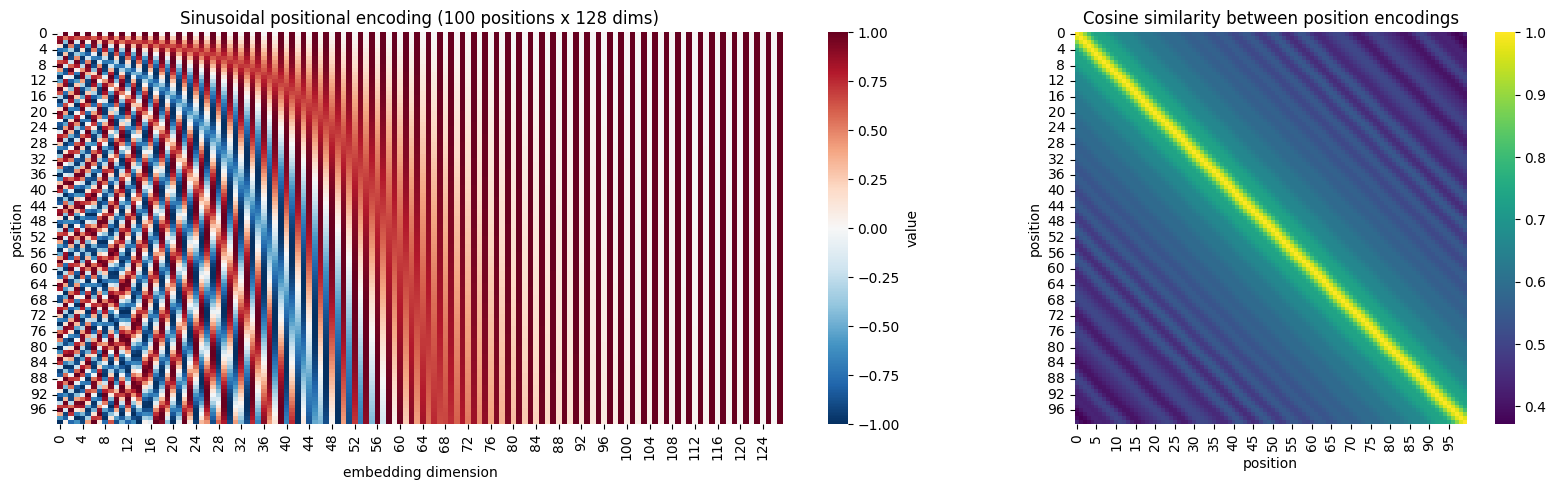

In [10]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)                                       # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))  # 1 / 10000^(2i/d)
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)      # even dimensions
        pe[:, 1::2] = torch.cos(position * div_term)      # odd dimensions
        self.register_buffer("pe", pe.unsqueeze(0))       # (1, max_len, d_model): moves with .to(device), not trained

    def forward(self, x):
        # x: (B, T, d_model) -> add the encoding of positions 0..T-1
        return x + self.pe[:, :x.size(1)]

pe_matrix = PositionalEncoding(d_model=128, max_len=100).pe[0].numpy()     # (positions, dims)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.6, 1]})
sns.heatmap(pe_matrix, cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "value"})
axes[0].set(title="Sinusoidal positional encoding (100 positions x 128 dims)",
            xlabel="embedding dimension", ylabel="position")
# cosine similarity between positions: nearby positions get similar encodings
unit = pe_matrix / np.linalg.norm(pe_matrix, axis=1, keepdims=True)
sns.heatmap(unit @ unit.T, cmap="viridis", ax=axes[1], square=True)
axes[1].set(title="Cosine similarity between position encodings", xlabel="position", ylabel="position")
plt.tight_layout(); plt.show()

### 3.4 Transformer Encoder Block
Implement `EncoderBlock(d_model, num_heads, d_ff, dropout)`:

`x → MHA → Dropout → Add & LayerNorm → FeedForward (Linear-GELU-Linear) → Dropout → Add & LayerNorm`

Then answer in markdown: **Why are residual connections and LayerNorm needed in deep Transformers?**

In [11]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = self.norm1(x + self.dropout1(self.mha(x, mask)))     # MHA -> Dropout -> Add & LayerNorm
        x = self.norm2(x + self.dropout2(self.ffn(x)))           # FFN -> Dropout -> Add & LayerNorm
        return x

# shape test: output must have the same shape as the input so blocks can be stacked
block = EncoderBlock(d_model=128, num_heads=4, d_ff=256)
x = torch.randn(2, 10, 128)
pad = torch.ones(2, 10, dtype=torch.long); pad[1, 7:] = 0
y = block(x, pad[:, None, None, :])
print("in:", tuple(x.shape), "-> out:", tuple(y.shape), "| attention weights:", tuple(block.mha.attn_weights.shape))
print(f"parameters per block: {count_params(block):,}")

in: (2, 10, 128) -> out: (2, 10, 128) | attention weights: (2, 4, 10, 10)
parameters per block: 132,480


**Why are residual connections and LayerNorm needed in deep Transformers?**

* **Residual connections** ($x + \text{SubLayer}(x)$) give the gradient an identity path from the loss straight to the lower layers. Without them, gradients must pass through every attention/FFN layer and tend to vanish or explode as depth grows (BERT-base has 12 blocks = 24 sub-layers). Each sub-layer then only has to learn a *refinement* of its input, so a freshly initialised block is close to the identity and deep stacks are easy to optimise. The token's own information (embedding and position) is also carried upward, so it isn't lost when attention mixes tokens together.
* **LayerNorm** re-centres and re-scales each token's vector to zero mean and unit variance (plus a learned gain and bias). Adding residuals layer after layer would otherwise make activation magnitudes drift and grow. LayerNorm keeps them on a stable scale, so the attention scores (and the softmax, see Part 2.3) and the GELU stay in a well-behaved range. That allows higher learning rates (our mini-model trains stably at lr = 1e-3) and faster, steadier convergence. It normalises per token rather than per batch, so it works with variable-length, padded sequences and small batches, unlike BatchNorm.

## Part 4: Mini-Transformer Classifier Trained from Scratch (15 points)

### 4.1 Build the model
Create `MiniTransformerClassifier` using: token embedding (use the BERT tokenizer's vocab size) → positional encoding → **2** `EncoderBlock`s (`d_model=128`, `heads=4`, `d_ff=256`) → mean-pool over non-padding tokens → `Linear(d_model, 2)`.
Print the number of trainable parameters.

In [12]:
class MiniTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, d_ff=256, num_layers=2,
                 num_classes=2, dropout=0.1, max_len=512, pad_id=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_enc = PositionalEncoding(d_model, max_len)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, num_heads, d_ff, dropout) for _ in range(num_layers)])
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        mask = attention_mask[:, None, None, :]                    # (B, 1, 1, T) padding mask for attention
        x = self.dropout(self.pos_enc(self.embedding(input_ids)))  # (B, T, d_model)
        for block in self.blocks:
            x = block(x, mask)
        m = attention_mask.unsqueeze(-1).to(x.dtype)               # (B, T, 1)
        pooled = (x * m).sum(dim=1) / m.sum(dim=1).clamp(min=1)    # mean over the non-padding tokens only
        return self.classifier(pooled)                             # (B, num_classes) logits

set_seed()
mini_model = MiniTransformerClassifier(tokenizer.vocab_size, pad_id=tokenizer.pad_token_id).to(device)
n_mini = count_params(mini_model)
print(mini_model)
print(f"\nTrainable parameters: {n_mini:,}")
print(f"  token embedding  : {mini_model.embedding.weight.numel():,}  ({mini_model.embedding.weight.numel() / n_mini:.1%})")
print(f"  2 encoder blocks : {count_params(mini_model.blocks):,}")
print(f"  classifier       : {count_params(mini_model.classifier):,}")

MiniTransformerClassifier(
  (embedding): Embedding(30522, 128, padding_idx=0)
  (pos_enc): PositionalEncoding()
  (dropout): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-1): 2 x EncoderBlock(
      (mha): MultiHeadAttention(
        (W_q): Linear(in_features=128, out_features=128, bias=True)
        (W_k): Linear(in_features=128, out_features=128, bias=True)
        (W_v): Linear(in_features=128, out_features=128, bias=True)
        (W_o): Linear(in_features=128, out_features=128, bias=True)
      )
      (ffn): Sequential(
        (0): Linear(in_features=128, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=128, bias=True)
      )
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  )
  (classifier): Linear(in_featu

### 4.2 Train
Write a standard PyTorch training loop (AdamW, lr=1e-3, 5 epochs, batch size 32). Log train loss and validation accuracy per epoch and plot both curves.
Note the padding mask must be built from `attention_mask` and reshaped to `(B, 1, 1, T)`.

Epoch 1/5 | train loss 0.6743 | train acc 0.5952 | val acc 0.6510
Epoch 2/5 | train loss 0.5854 | train acc 0.6900 | val acc 0.6820
Epoch 3/5 | train loss 0.4878 | train acc 0.7702 | val acc 0.7340
Epoch 4/5 | train loss 0.3923 | train acc 0.8254 | val acc 0.7380
Epoch 5/5 | train loss 0.3125 | train acc 0.8728 | val acc 0.7540

Total training time: 10.5 s | best val acc 0.7540 (epoch 5, weights restored)


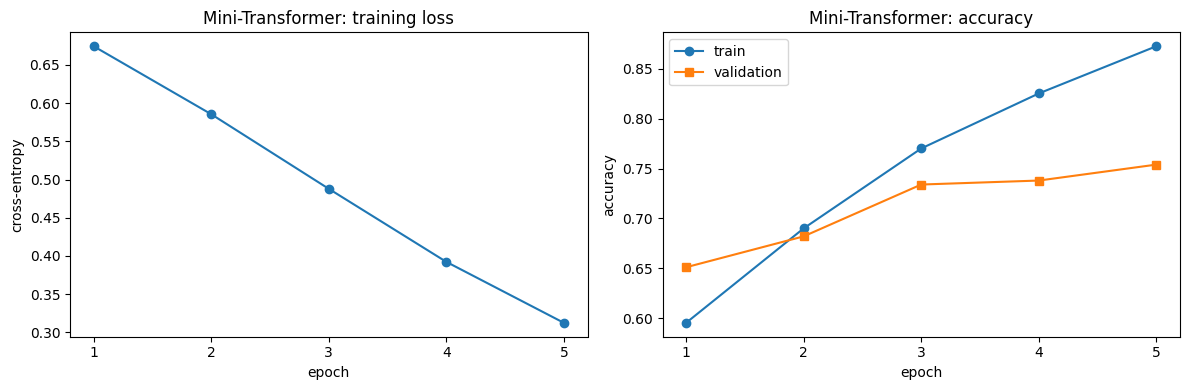

In [13]:
BATCH_SIZE, EPOCHS, LR = 32, 5, 1e-3

train_loader = DataLoader(tokenized["train"], batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=data_collator, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(tokenized["validation"], batch_size=128, collate_fn=data_collator)
test_loader = DataLoader(tokenized["test"], batch_size=128, collate_fn=data_collator)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for batch in loader:
        logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        preds.append(logits.argmax(-1).cpu())
        labels.append(batch["labels"])
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

optimizer = torch.optim.AdamW(mini_model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()
history = {"train_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = -1.0, None

if device.type == "cuda": torch.cuda.synchronize()
start = time.time()
for epoch in range(1, EPOCHS + 1):
    mini_model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        logits = mini_model(input_ids, attention_mask)
        loss = loss_fn(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(mini_model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(-1) == labels).sum().item()
        seen += labels.size(0)

    val_preds, val_labels = predict(mini_model, val_loader)
    val_acc = accuracy_score(val_labels, val_preds)
    history["train_loss"].append(total_loss / seen)
    history["train_acc"].append(correct / seen)
    history["val_acc"].append(val_acc)
    if val_acc > best_val_acc:                       # keep the best epoch (selected on validation, not test)
        best_val_acc, best_state = val_acc, copy.deepcopy(mini_model.state_dict())
    print(f"Epoch {epoch}/{EPOCHS} | train loss {total_loss / seen:.4f} | train acc {correct / seen:.4f} | val acc {val_acc:.4f}")

if device.type == "cuda": torch.cuda.synchronize()
mini_train_time = time.time() - start
mini_model.load_state_dict(best_state)
print(f"\nTotal training time: {mini_train_time:.1f} s | best val acc {best_val_acc:.4f} "
      f"(epoch {int(np.argmax(history['val_acc'])) + 1}, weights restored)")

epochs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history["train_loss"], "o-")
ax[0].set(title="Mini-Transformer: training loss", xlabel="epoch", ylabel="cross-entropy")
ax[1].plot(epochs, history["train_acc"], "o-", label="train")
ax[1].plot(epochs, history["val_acc"], "s-", label="validation")
ax[1].set(title="Mini-Transformer: accuracy", xlabel="epoch", ylabel="accuracy")
ax[1].legend()
for a in ax: a.set_xticks(list(epochs))
plt.tight_layout(); plt.show()

### 4.3 Evaluate
Report accuracy, F1 and the confusion matrix on the test set. Record the **total training time**.

Mini-Transformer (test, n=872)
  accuracy      : 0.7156
  F1 (positive) : 0.7304
  training time : 10.5 s


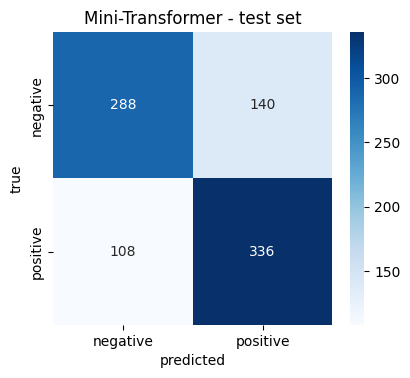

confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:
 [[288 140]
 [108 336]]


In [14]:
def plot_confusion(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(4.5, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_names, yticklabels=label_names)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(title)
    plt.show()
    return cm

start = time.time()
mini_preds, test_labels = predict(mini_model, test_loader)
mini_infer_time = time.time() - start

mini_acc, mini_f1 = accuracy_score(test_labels, mini_preds), f1_score(test_labels, mini_preds)
print(f"Mini-Transformer (test, n={len(test_labels)})")
print(f"  accuracy      : {mini_acc:.4f}")
print(f"  F1 (positive) : {mini_f1:.4f}")
print(f"  training time : {mini_train_time:.1f} s")
cm = plot_confusion(test_labels, mini_preds, "Mini-Transformer - test set")
print("confusion matrix [rows = true neg/pos, cols = predicted neg/pos]:\n", cm)

results["Mini-Transformer (scratch)"] = {
    "Params": n_mini, "Trainable": n_mini, "Pre-trained": "No",
    "Test Acc": mini_acc, "Test F1": mini_f1,
    "Train time (s)": mini_train_time, "Test inference (s)": mini_infer_time,
}

## Part 5: Fine-Tuning BERT (20 points)

### 5.1 Load the pre-trained model
Load `AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)`. Print the parameter count and compare it with your mini-Transformer.

In [15]:
id2label = {0: "NEGATIVE", 1: "POSITIVE"}
label2id = {v: k for k, v in id2label.items()}

def load_classifier(name=MODEL_NAME, **kwargs):
    return AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=2, id2label=id2label, label2id=label2id, **kwargs)

set_seed()
bert_model = load_classifier()
n_bert = count_params(bert_model)

print(f"BERT-base parameters    : {n_bert:,}")
print(f"  embeddings            : {count_params(bert_model.bert.embeddings):,}")
print(f"  12 encoder layers     : {count_params(bert_model.bert.encoder):,}")
print(f"  pooler                : {count_params(bert_model.bert.pooler):,}")
print(f"  classifier head (new) : {count_params(bert_model.classifier):,}")
print(f"\nMini-Transformer       : {n_mini:,}")
print(f"BERT-base is {n_bert / n_mini:.1f}x larger "
      f"(12 layers / 12 heads / d_model 768 vs 2 layers / 4 heads / d_model 128)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT-base parameters    : 109,483,778
  embeddings            : 23,837,184
  12 encoder layers     : 85,054,464
  pooler                : 590,592
  classifier head (new) : 1,538

Mini-Transformer       : 4,172,034
BERT-base is 26.2x larger (12 layers / 12 heads / d_model 768 vs 2 layers / 4 heads / d_model 128)


### 5.2 Metrics
Define `compute_metrics` that returns **accuracy** and **F1** (use `evaluate` or `sklearn`).

In [16]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

### 5.3 Configure and run training
Use `TrainingArguments`: `learning_rate=2e-5`, `num_train_epochs=3`, `per_device_train_batch_size=32`, `weight_decay=0.01`, `eval_strategy="epoch"`, `fp16=True` (GPU), `report_to="none"`. Train with `Trainer` and record training time.

{'loss': '0.4006', 'grad_norm': '3.415', 'learning_rate': '1.338e-05', 'epoch': '1'}
{'eval_loss': '0.2366', 'eval_accuracy': '0.911', 'eval_f1': '0.9187', 'eval_runtime': '0.7115', 'eval_samples_per_second': '1405', 'eval_steps_per_second': '11.24', 'epoch': '1'}
{'loss': '0.1966', 'grad_norm': '10.11', 'learning_rate': '6.709e-06', 'epoch': '2'}
{'eval_loss': '0.2261', 'eval_accuracy': '0.916', 'eval_f1': '0.9245', 'eval_runtime': '0.7439', 'eval_samples_per_second': '1344', 'eval_steps_per_second': '10.76', 'epoch': '2'}
{'loss': '0.1093', 'grad_norm': '0.4699', 'learning_rate': '4.246e-08', 'epoch': '3'}
{'eval_loss': '0.2863', 'eval_accuracy': '0.912', 'eval_f1': '0.9207', 'eval_runtime': '0.8074', 'eval_samples_per_second': '1238', 'eval_steps_per_second': '9.908', 'epoch': '3'}
{'train_runtime': '41.36', 'train_samples_per_second': '362.6', 'train_steps_per_second': '11.39', 'train_loss': '0.2355', 'epoch': '3'}

Training time: 41.8 s


,train_loss,eval_loss,eval_accuracy,eval_f1
epoch,,,,
1.0,0.400602,0.236606,0.911,0.918721
2.0,0.196555,0.226051,0.916,0.924460
3.0,0.109304,0.286276,0.912,0.920721


BERT (full fine-tune) (test) | accuracy 0.8968 | F1 0.8996 | training time 41.8 s


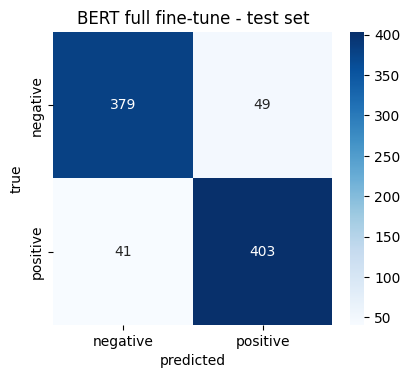

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('bert-sst2-full/tokenizer_config.json', 'bert-sst2-full/tokenizer.json')

In [17]:
def train_with_trainer(model, run_name, lr=2e-5, train_ds=None, val_ds=None, collator=None, epochs=3):
    args = TrainingArguments(
        output_dir=f"runs/{run_name}",
        learning_rate=lr,
        num_train_epochs=epochs,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=128,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="no",               # no 400 MB checkpoint every epoch; the final model is saved manually
        logging_strategy="epoch",
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds if train_ds is not None else tokenized["train"],
        eval_dataset=val_ds if val_ds is not None else tokenized["validation"],
        data_collator=collator if collator is not None else data_collator,
        compute_metrics=compute_metrics,
    )
    start = time.time()
    trainer.train()
    return trainer, time.time() - start

def epoch_table(trainer):
    logs = pd.DataFrame(trainer.state.log_history)
    train = logs.dropna(subset=["loss"])[["epoch", "loss"]].rename(columns={"loss": "train_loss"})
    evals = logs.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]]
    train["epoch"], evals["epoch"] = train["epoch"].round(2), evals["epoch"].round(2)
    return train.merge(evals, on="epoch").set_index("epoch")

def evaluate_on_test(name, trainer, test_ds, n_params, n_trainable, train_time):
    out = trainer.predict(test_ds)                           # metrics are prefixed with "test_"
    preds = out.predictions.argmax(-1)
    acc, f1 = out.metrics["test_accuracy"], out.metrics["test_f1"]
    print(f"{name} (test) | accuracy {acc:.4f} | F1 {f1:.4f} | training time {train_time:.1f} s")
    results[name] = {
        "Params": n_params, "Trainable": n_trainable, "Pre-trained": "Yes",
        "Test Acc": acc, "Test F1": f1,
        "Train time (s)": train_time, "Test inference (s)": out.metrics["test_runtime"],
    }
    return preds, out.label_ids

full_trainer, full_time = train_with_trainer(bert_model, "bert-full", lr=2e-5)
print(f"\nTraining time: {full_time:.1f} s")
display(epoch_table(full_trainer))

full_preds, full_labels = evaluate_on_test("BERT (full fine-tune)", full_trainer, tokenized["test"],
                                           n_bert, n_bert, full_time)
plot_confusion(full_labels, full_preds, "BERT full fine-tune - test set")

FULL_DIR = "bert-sst2-full"
full_trainer.save_model(FULL_DIR)              # reused for the pipeline (5.5) and attention plots (Part 6)
tokenizer.save_pretrained(FULL_DIR)

### 5.4 Ablation: frozen vs. full fine-tuning
Re-load a fresh BERT and **freeze all encoder layers** (`for p in model.bert.parameters(): p.requires_grad = False`) so only the classifier head trains. Train with the same settings (you may use lr=1e-3).
Report a table with *trainable parameters*, *accuracy*, *F1*, and *training time* for: frozen BERT vs. fully fine-tuned BERT.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Trainable parameters: 1,538 of 109,483,778 (0.0014%)
{'loss': '0.6565', 'grad_norm': '1.751', 'learning_rate': '0.0006688', 'epoch': '1'}
{'eval_loss': '0.6034', 'eval_accuracy': '0.692', 'eval_f1': '0.7762', 'eval_runtime': '0.8177', 'eval_samples_per_second': '1223', 'eval_steps_per_second': '9.783', 'epoch': '1'}
{'loss': '0.619', 'grad_norm': '4.526', 'learning_rate': '0.0003355', 'epoch': '2'}
{'eval_loss': '0.5786', 'eval_accuracy': '0.687', 'eval_f1': '0.7766', 'eval_runtime': '0.8415', 'eval_samples_per_second': '1188', 'eval_steps_per_second': '9.507', 'epoch': '2'}
{'loss': '0.5999', 'grad_norm': '4.391', 'learning_rate': '2.123e-06', 'epoch': '3'}
{'eval_loss': '0.5702', 'eval_accuracy': '0.724', 'eval_f1': '0.7909', 'eval_runtime': '0.8406', 'eval_samples_per_second': '1190', 'eval_steps_per_second': '9.517', 'epoch': '3'}
{'train_runtime': '14.75', 'train_samples_per_second': '1017', 'train_steps_per_second': '31.93', 'train_loss': '0.6251', 'epoch': '3'}

Training time: 1

,train_loss,eval_loss,eval_accuracy,eval_f1
epoch,,,,
1.0,0.656532,0.603391,0.692,0.776163
2.0,0.618995,0.578621,0.687,0.776588
3.0,0.599865,0.570162,0.724,0.790909


BERT (frozen, head only) (test) | accuracy 0.7007 | F1 0.7545 | training time 15.1 s


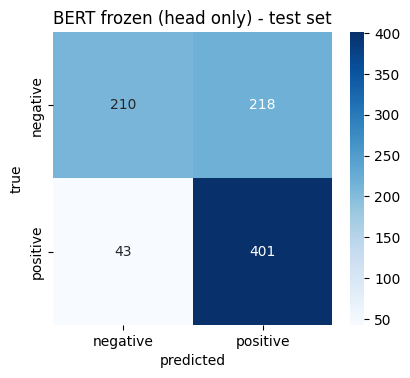

,Trainable params,Accuracy,F1,Training time (s)
"BERT (frozen, head only)","1,538",0.7007,0.7545,15.1
BERT (full fine-tune),"109,483,778",0.8968,0.8996,41.8


In [18]:
# free the GPU memory of the fully fine-tuned model (it is saved in FULL_DIR)
for _name in ["bert_model", "full_trainer"]:
    globals().pop(_name, None)
torch.cuda.empty_cache()

set_seed()
frozen_model = load_classifier()
for p in frozen_model.bert.parameters():       # embeddings + 12 encoder layers + pooler
    p.requires_grad = False
n_frozen_trainable = count_params(frozen_model)
print(f"Trainable parameters: {n_frozen_trainable:,} of {count_params(frozen_model, trainable_only=False):,} "
      f"({n_frozen_trainable / n_bert:.4%})")

frozen_trainer, frozen_time = train_with_trainer(frozen_model, "bert-frozen", lr=1e-3)
print(f"\nTraining time: {frozen_time:.1f} s")
display(epoch_table(frozen_trainer))

frozen_preds, _ = evaluate_on_test("BERT (frozen, head only)", frozen_trainer, tokenized["test"],
                                   n_bert, n_frozen_trainable, frozen_time)
plot_confusion(full_labels, frozen_preds, "BERT frozen (head only) - test set")

ablation = pd.DataFrame({k: results[k] for k in ["BERT (frozen, head only)", "BERT (full fine-tune)"]}).T
ablation = ablation[["Trainable", "Test Acc", "Test F1", "Train time (s)"]]
ablation.columns = ["Trainable params", "Accuracy", "F1", "Training time (s)"]
display(ablation.style.format({"Trainable params": "{:,}", "Accuracy": "{:.4f}",
                               "F1": "{:.4f}", "Training time (s)": "{:.1f}"}))

**Frozen vs. full fine-tuning (measured).**

| | Trainable params | Test Acc | Test F1 | Train time |
|---|---|---|---|---|
| BERT frozen (head only, lr 1e-3) | 1,538 (0.0014%) | 0.7007 | 0.7545 | 15.1 s |
| BERT full fine-tune (lr 2e-5) | 109,483,778 | **0.8968** | **0.8996** | 41.8 s |

* **Full fine-tuning is ~20 accuracy points better.** When frozen, BERT is a fixed feature extractor, and its pooled `[CLS]` vector was trained for NSP, not sentiment, so a single linear layer cannot separate the classes well. The frozen head is still under-fitting after 3 epochs (training loss only fell from 0.66 to 0.60, against 0.11 for full fine-tuning).
* **The frozen model's F1 is misleading.** Its confusion matrix shows it predicts *positive* far too often: 218 of 428 negative reviews are labelled positive (negative recall 49%, positive recall 90%). F1 is computed for the positive class, so this bias inflates it (0.75) while accuracy is only 0.70. Full fine-tuning has balanced errors (49 FP / 41 FN).
* **Speed:** frozen training was 2.8x faster (15.1 s vs 41.8 s), because no gradients or optimizer states are computed for the encoder. The forward pass through all 12 layers is still required, though, so the speed-up is tiny compared with the 71,000x reduction in trainable parameters. Inference cost is identical for both.

### 5.5 Inference
Use `pipeline("text-classification", model=..., tokenizer=...)` to classify these sentences, and add **3 of your own** (include one sarcastic and one negated sentence):
```python
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
]
```

In [19]:
tests = [
    "This movie was an absolute masterpiece.",
    "I wasted two hours of my life on this film.",
    "The acting was not bad at all.",
    "The plot was predictable, but the visuals were stunning.",
    # my own sentences
    "Oh brilliant, yet another two-hour nap disguised as a thriller.",      # sarcastic
    "This is not a film I would recommend to anyone.",                       # negated
    "The cast is wonderful, but the script gives them nothing to do.",       # contrast / mixed
]

pipe_device = 0 if torch.cuda.is_available() else -1
clf_full = pipeline("text-classification", model=FULL_DIR, tokenizer=FULL_DIR, device=pipe_device)
clf_frozen = pipeline("text-classification", model=frozen_trainer.model, tokenizer=tokenizer, device=pipe_device)

rows = []
for s, f, z in zip(tests, clf_full(tests), clf_frozen(tests)):
    rows.append({"sentence": s,
                 "full fine-tune": f"{f['label']} ({f['score']:.3f})",
                 "frozen BERT": f"{z['label']} ({z['score']:.3f})"})
pd.set_option("display.max_colwidth", 100)
display(pd.DataFrame(rows))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,sentence,full fine-tune,frozen BERT
0,This movie was an absolute masterpiece.,POSITIVE (0.996),POSITIVE (0.630)
1,I wasted two hours of my life on this film.,NEGATIVE (0.987),NEGATIVE (0.611)
2,The acting was not bad at all.,POSITIVE (0.915),POSITIVE (0.525)
3,"The plot was predictable, but the visuals were stunning.",POSITIVE (0.995),POSITIVE (0.774)
4,"Oh brilliant, yet another two-hour nap disguised as a thriller.",POSITIVE (0.911),POSITIVE (0.601)
5,This is not a film I would recommend to anyone.,NEGATIVE (0.987),POSITIVE (0.504)
6,"The cast is wonderful, but the script gives them nothing to do.",NEGATIVE (0.991),NEGATIVE (0.505)


**Observations.**
* **Clear sentences (1, 2):** the fully fine-tuned model is correct and very confident (0.996 / 0.987).
* **Negation:** fine-tuned BERT handles both negated sentences. "*not bad at all*" → POSITIVE (0.915) and "*not a film I would recommend*" → NEGATIVE (0.987). Bidirectional self-attention lets *not* change the meaning of *bad* / *recommend* (Part 6 shows attention links between *not* and *bad*). The frozen model gets the second one wrong (POSITIVE 0.504) and is barely above chance on the first (0.525). It behaves much more like a bag of words.
* **Contrast with "but":** both mixed sentences follow the clause *after* "but". "*predictable, but the visuals were stunning*" → POSITIVE (0.995) and "*wonderful, but the script gives them nothing to do*" → NEGATIVE (0.991). The model has learned the SST-2 convention that the clause after *but* carries the overall verdict.
* **Sarcasm fails:** "*Oh brilliant, yet another two-hour nap disguised as a thriller*" → POSITIVE (0.911). The surface words (*brilliant*, *thriller*) are positive, and the negative meaning comes only from tone and world knowledge ("nap" = boring), which 5,000 labelled sentences do not teach.
* The frozen model's confidences are all between 0.50 and 0.77, consistent with its weak 70% test accuracy.

## Part 6: Visualising Attention Heads (10 points)

### 6.1 Extract attentions
Load your fine-tuned BERT with `output_attentions=True` and run one sentence. `outputs.attentions` is a tuple of 12 tensors with shape `(1, 12, T, T)` — one per layer.

In [20]:
# "eager" attention is needed: the fused SDPA kernel does not return attention weights
attn_model = AutoModelForSequenceClassification.from_pretrained(
    FULL_DIR, output_attentions=True, attn_implementation="eager").to(device).eval()

sentence = "The acting was not bad at all, but the plot was painfully slow."
inputs = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = attn_model(**inputs)

attentions = tuple(a.detach().cpu() for a in outputs.attentions)   # 12 x (1, 12, T, T)
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
probs = torch.softmax(outputs.logits, -1)[0].cpu()

print("sentence     :", sentence)
print("tokens       :", tokens)
print("prediction   :", id2label[int(probs.argmax())], f"(P(pos) = {probs[1]:.3f})")
print("# layers     :", len(attentions))
print("shape / layer:", tuple(attentions[0].shape), "= (batch, heads, T, T)")
print("rows sum to 1:", torch.allclose(attentions[0].sum(-1), torch.ones(1, 12, len(tokens)), atol=1e-4))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentence     : The acting was not bad at all, but the plot was painfully slow.
tokens       : ['[CLS]', 'the', 'acting', 'was', 'not', 'bad', 'at', 'all', ',', 'but', 'the', 'plot', 'was', 'painfully', 'slow', '.', '[SEP]']
prediction   : NEGATIVE (P(pos) = 0.007)
# layers     : 12
shape / layer: (1, 12, 17, 17) = (batch, heads, T, T)
rows sum to 1: True


### 6.2 Heatmaps
Plot a **grid of 4 heads** (e.g. layer 1 vs layer 12, two heads each) as heatmaps with tokens on the axes. Then use `bertviz` (`head_view` or `model_view`) to produce an interactive view.

> In Colab the `bertviz` call must be the last line of the cell.

Strongest head for each pattern (layer / head are 1-indexed):
  previous token : layer  2, head  5  -> avg weight 0.65
  next token     : layer  3, head 10  -> avg weight 0.94
  [CLS]          : layer  2, head  7  -> avg weight 0.86
  [SEP]          : layer  6, head  2  -> avg weight 0.92
  itself         : layer  3, head  7  -> avg weight 0.44


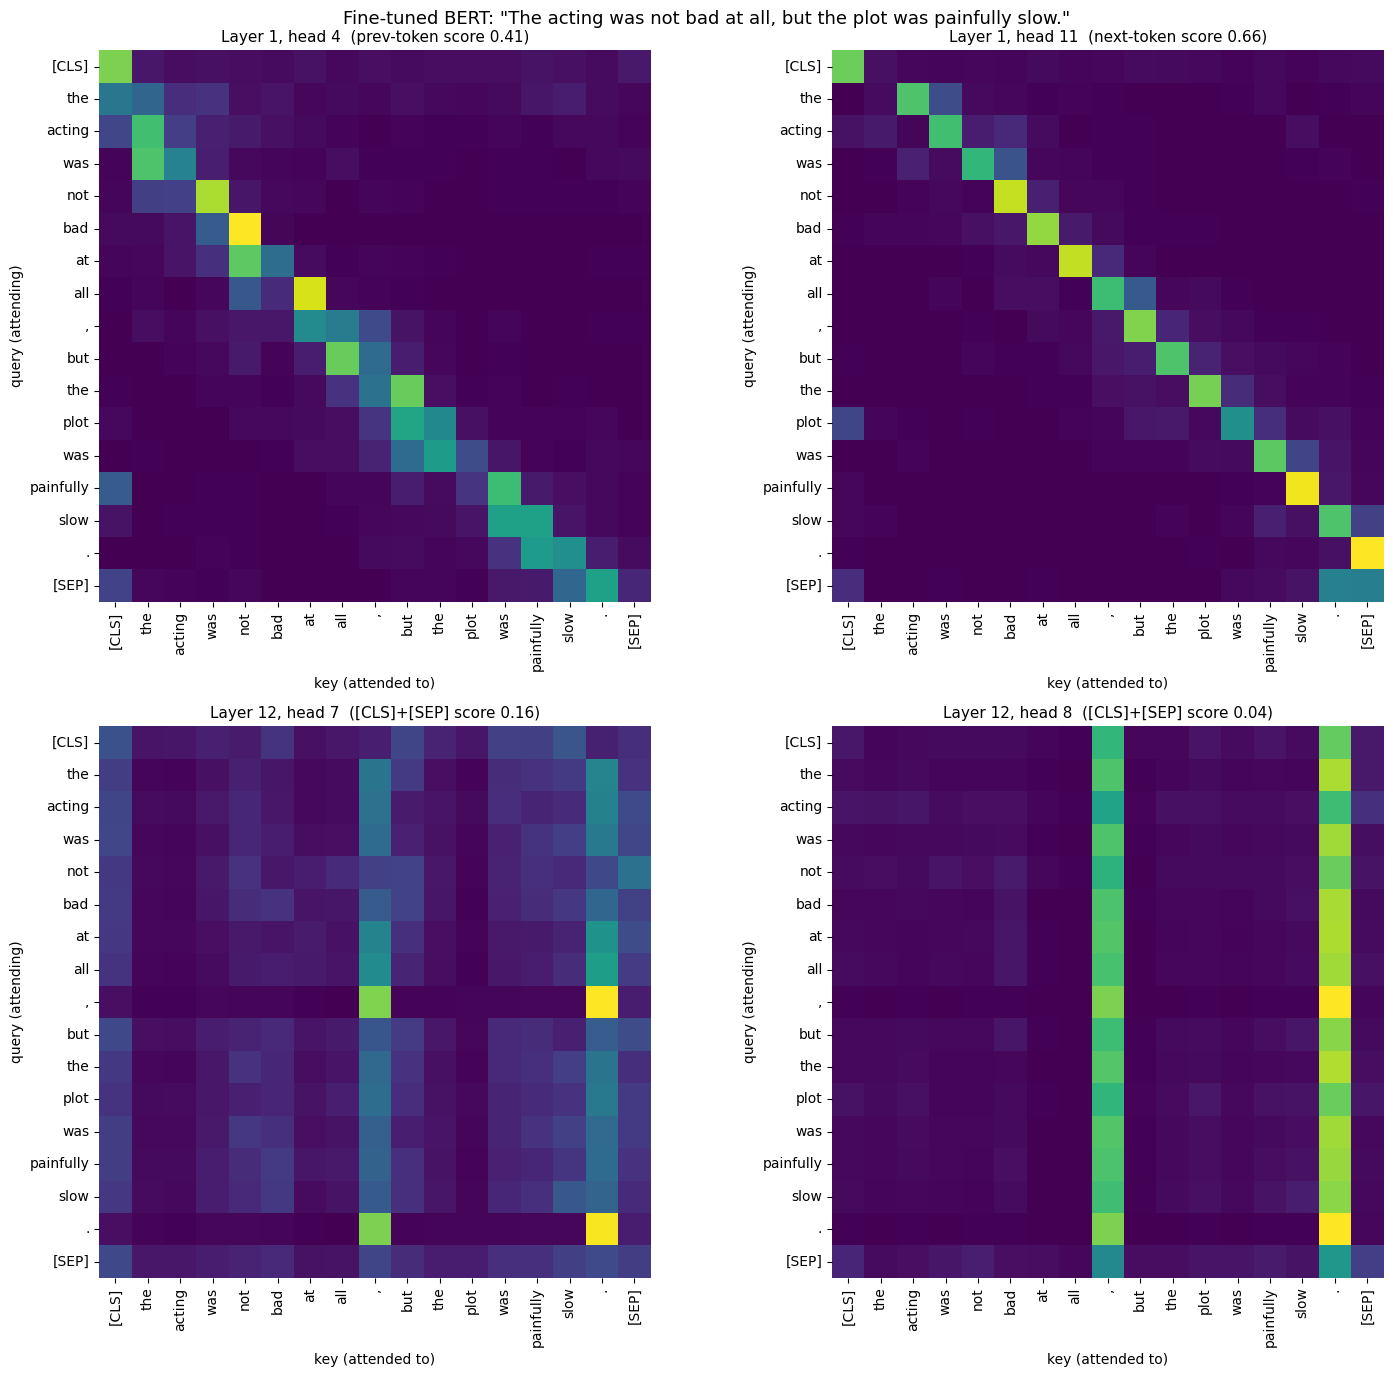

In [21]:
A = torch.stack([a[0] for a in attentions]).numpy()          # (layers, heads, T, T)
L, H, T, _ = A.shape
idx = np.arange(T)

# how much (on average over query tokens) each head looks at a given target
pattern_scores = {
    "previous token": A[:, :, idx[1:], idx[:-1]].mean(-1),   # query i -> key i-1
    "next token":     A[:, :, idx[:-1], idx[1:]].mean(-1),   # query i -> key i+1
    "[CLS]":          A[:, :, :, 0].mean(-1),
    "[SEP]":          A[:, :, :, T - 1].mean(-1),
    "itself":         A[:, :, idx, idx].mean(-1),
}
print("Strongest head for each pattern (layer / head are 1-indexed):")
for name, s in pattern_scores.items():
    l, h = np.unravel_index(s.argmax(), s.shape)
    print(f"  {name:15s}: layer {l + 1:2d}, head {h + 1:2d}  -> avg weight {s[l, h]:.2f}")

def plot_head(ax, attn, toks, title):
    sns.heatmap(attn, xticklabels=toks, yticklabels=toks, cmap="viridis", vmin=0, square=True,
                cbar=False, ax=ax)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("key (attended to)"); ax.set_ylabel("query (attending)")
    ax.tick_params(axis="x", rotation=90); ax.tick_params(axis="y", rotation=0)

# layer 1: the heads most focused on the previous / next token
prev1, next1 = pattern_scores["previous token"][0], pattern_scores["next token"][0]
h_prev = int(prev1.argmax())
h_next = int(next(h for h in np.argsort(-next1) if h != h_prev))
# layer 12: the head most / least focused on the special tokens
special12 = pattern_scores["[CLS]"][L - 1] + pattern_scores["[SEP]"][L - 1]
h_spec, h_content = int(special12.argmax()), int(special12.argmin())

chosen = [
    (0, h_prev, f"prev-token score {prev1[h_prev]:.2f}"),
    (0, h_next, f"next-token score {next1[h_next]:.2f}"),
    (L - 1, h_spec, f"[CLS]+[SEP] score {special12[h_spec]:.2f}"),
    (L - 1, h_content, f"[CLS]+[SEP] score {special12[h_content]:.2f}"),
]
fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, (l, h, info) in zip(axes.flat, chosen):
    plot_head(ax, A[l, h], tokens, f"Layer {l + 1}, head {h + 1}  ({info})")
plt.suptitle(f'Fine-tuned BERT: "{sentence}"', fontsize=13)
plt.tight_layout(); plt.show()

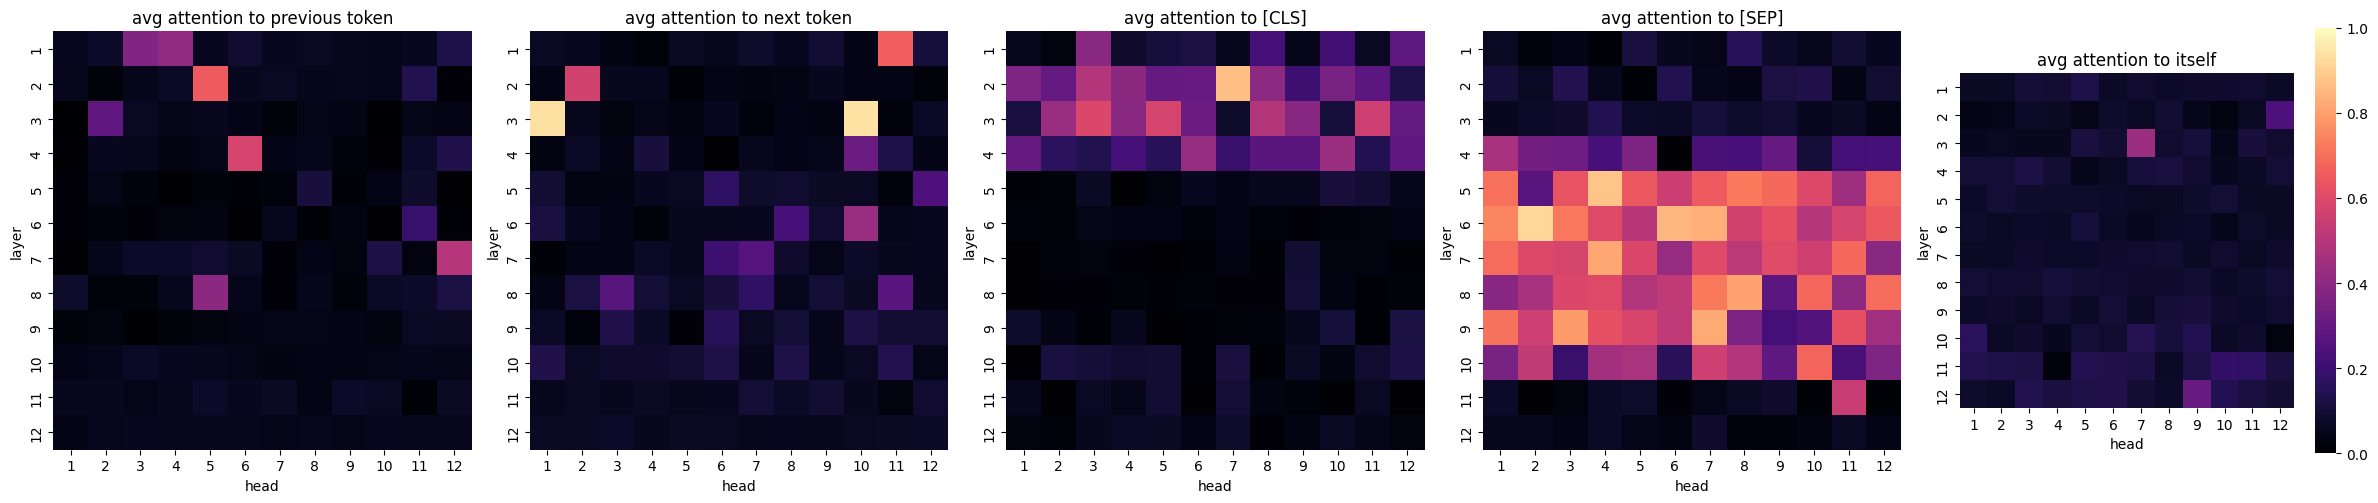

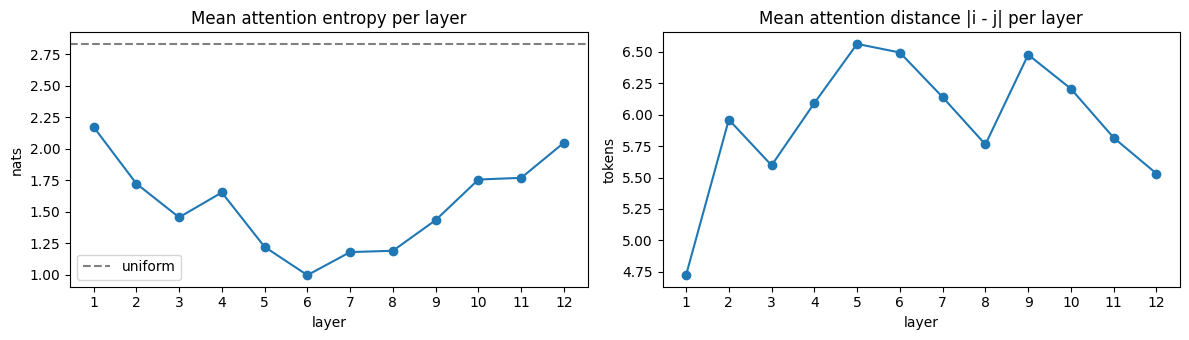

In [22]:
# overview of all 144 heads: which layers/heads implement which pattern
fig, axes = plt.subplots(1, len(pattern_scores), figsize=(24, 4.8))
for ax, (name, s) in zip(axes, pattern_scores.items()):
    sns.heatmap(s, cmap="magma", vmin=0, vmax=1, ax=ax, square=True,
                xticklabels=range(1, H + 1), yticklabels=range(1, L + 1), cbar=ax is axes[-1])
    ax.set(title=f"avg attention to {name}", xlabel="head", ylabel="layer")
plt.tight_layout(); plt.show()

# how "broad" attention is in each layer
entropy = -(A * np.log(A + 1e-12)).sum(-1).mean(axis=(1, 2))                 # (L,)
distance = (A * np.abs(idx[:, None] - idx[None, :])).sum(-1).mean(axis=(1, 2))  # (L,) avg |i-j|
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(range(1, L + 1), entropy, "o-"); ax[0].axhline(np.log(T), ls="--", c="gray", label="uniform")
ax[0].set(title="Mean attention entropy per layer", xlabel="layer", ylabel="nats"); ax[0].legend()
ax[1].plot(range(1, L + 1), distance, "o-")
ax[1].set(title="Mean attention distance |i - j| per layer", xlabel="layer", ylabel="tokens")
for a in ax: a.set_xticks(range(1, L + 1))
plt.tight_layout(); plt.show()

In [23]:
# interactive view: pick a layer, hover over a token (head_view must be the last line of the cell)
from bertviz import head_view
head_view(attentions, tokens)

<IPython.core.display.Javascript object>

In [24]:
# all 12 layers x 12 heads at once (click a thumbnail to enlarge)
from bertviz import model_view
model_view(attentions, tokens)

<IPython.core.display.Javascript object>

### 6.3 Interpret
In markdown, answer:
1. Do you find a head that mostly attends to the **next / previous token**? To `[SEP]` or `[CLS]`?
2. How do attention patterns differ between **early** and **late** layers?
3. Compare to your from-scratch model's `attn_weights` (Part 3). Are they as structured? Why / why not?

Mini-Transformer prediction: NEGATIVE (P(pos) = 0.013)


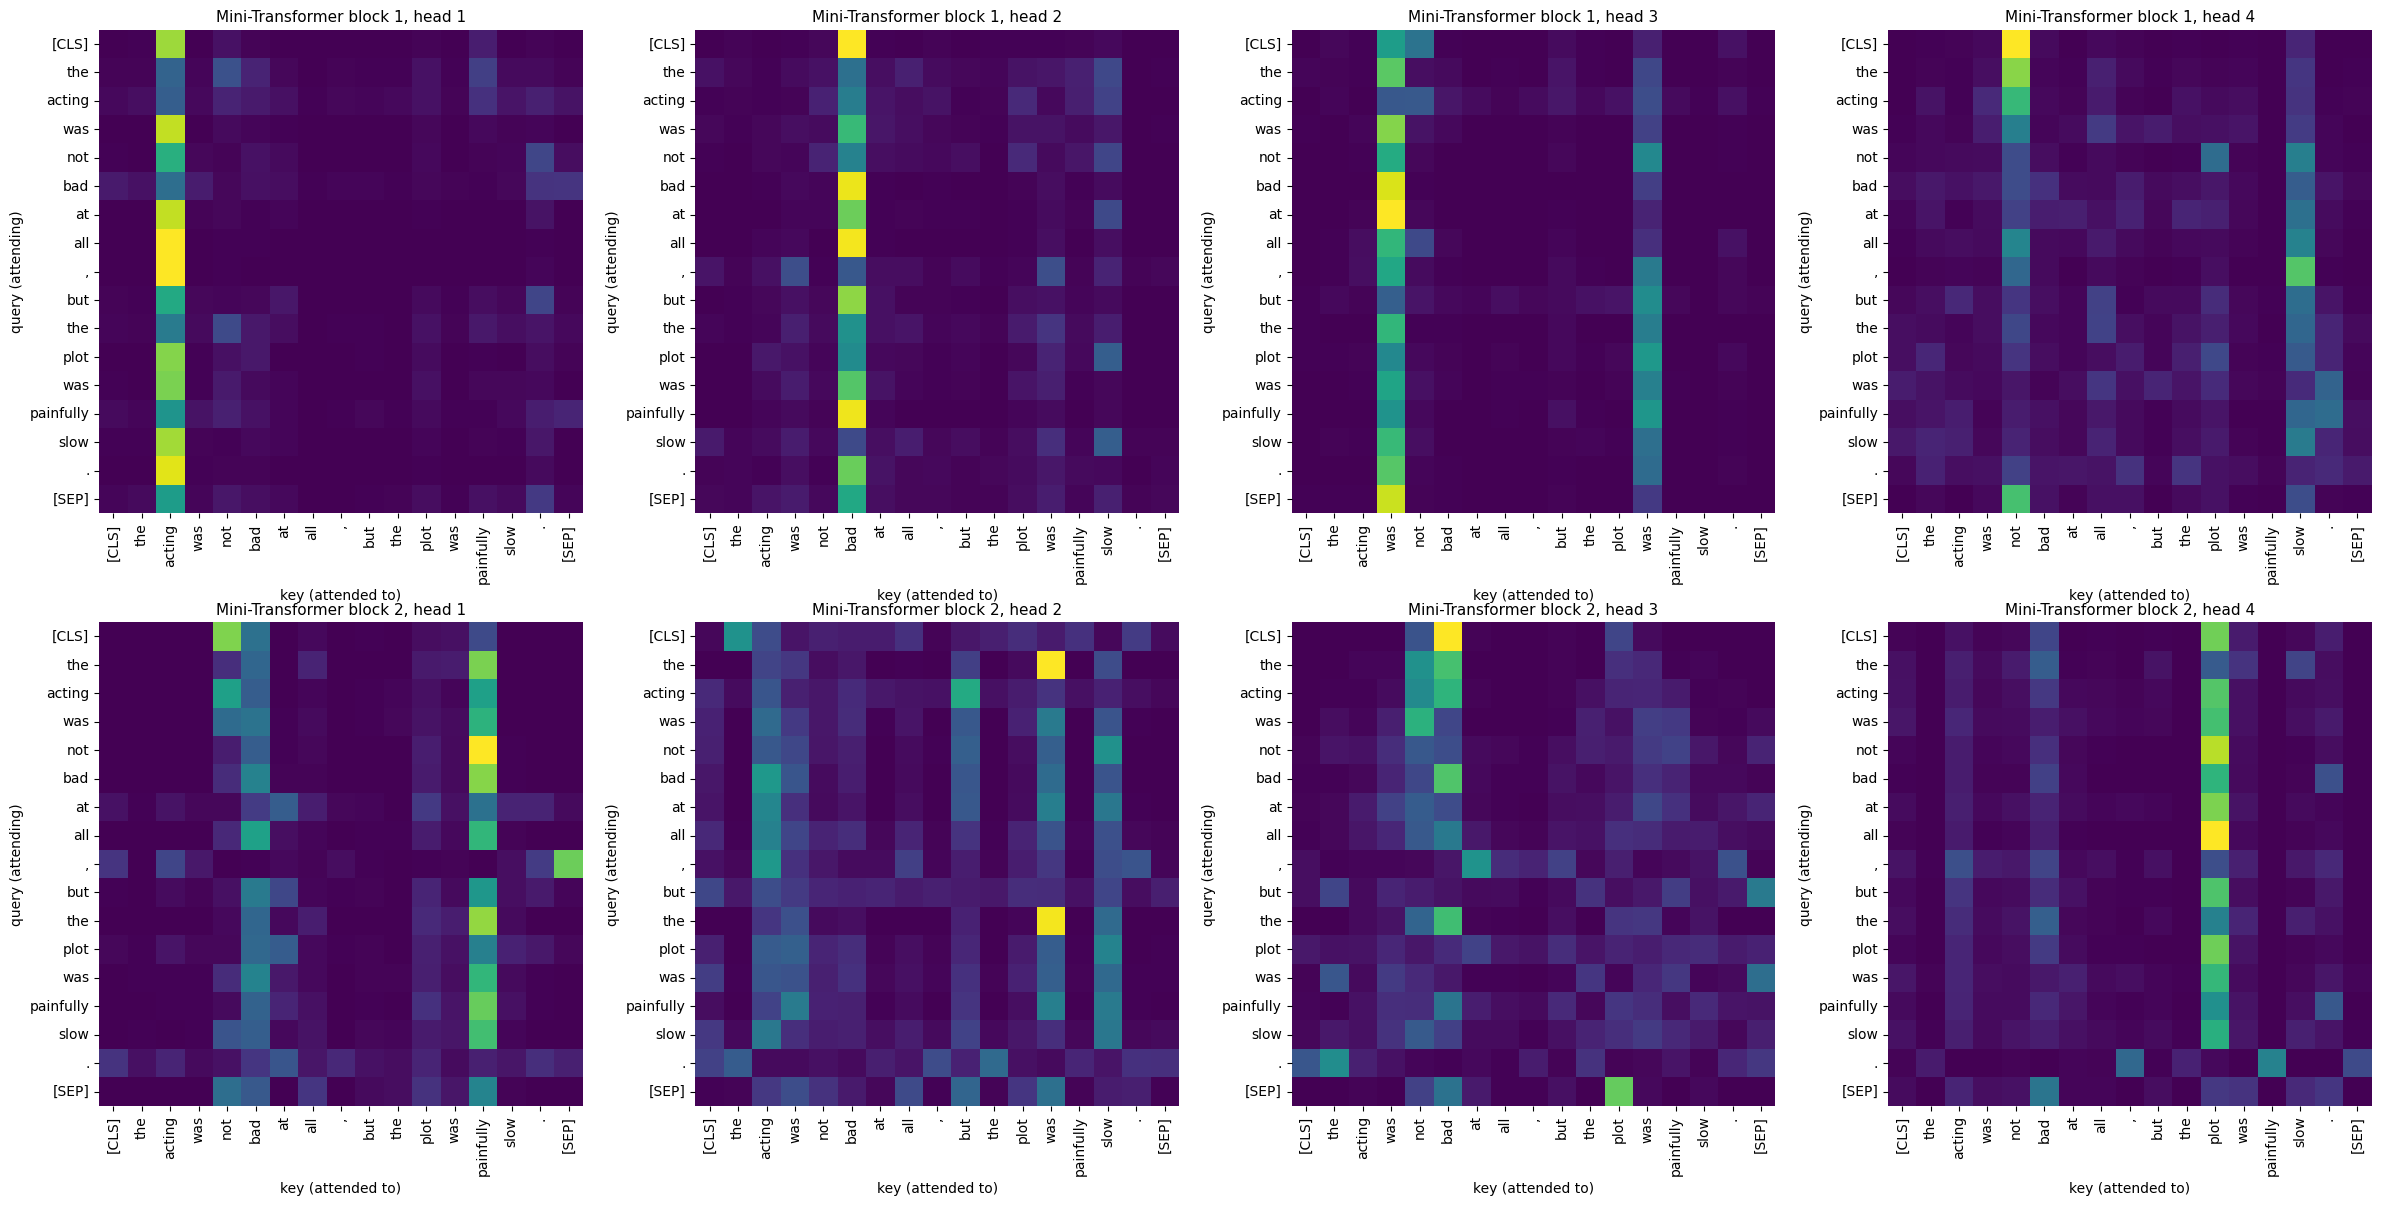

,BERT (fine-tuned),Mini-Transformer
max prev-token score,0.655,0.075
max next-token score,0.938,0.081
max [SEP] score,0.917,0.055
mean entropy (nats),1.549,1.648
uniform entropy,2.833,2.833


In [25]:
# same sentence through the from-scratch model; attn_weights were stored by our MultiHeadAttention layers
mini_model.eval()
mini_inputs = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    mini_probs = torch.softmax(mini_model(mini_inputs["input_ids"], mini_inputs["attention_mask"]), -1)[0].cpu()
print("Mini-Transformer prediction:", id2label[int(mini_probs.argmax())], f"(P(pos) = {mini_probs[1]:.3f})")

mini_A = np.stack([blk.mha.attn_weights[0].cpu().numpy() for blk in mini_model.blocks])   # (2, 4, T, T)
nL, nH = mini_A.shape[:2]
fig, axes = plt.subplots(nL, nH, figsize=(6 * nH, 6 * nL))
for l in range(nL):
    for h in range(nH):
        plot_head(axes[l, h], mini_A[l, h], tokens, f"Mini-Transformer block {l + 1}, head {h + 1}")
plt.tight_layout(); plt.show()

def head_summary(att):
    """att: (layers, heads, T, T) -> strongest prev/next/[SEP] head and mean entropy"""
    ent = -(att * np.log(att + 1e-12)).sum(-1).mean()
    return {
        "max prev-token score": att[:, :, idx[1:], idx[:-1]].mean(-1).max(),
        "max next-token score": att[:, :, idx[:-1], idx[1:]].mean(-1).max(),
        "max [SEP] score": att[:, :, :, T - 1].mean(-1).max(),
        "mean entropy (nats)": ent,
        "uniform entropy": np.log(T),
    }
display(pd.DataFrame({"BERT (fine-tuned)": head_summary(A),
                      "Mini-Transformer": head_summary(mini_A)}).round(3))

### 6.3 Answers

**1. Next / previous token, `[SEP]` / `[CLS]` heads: yes, clearly.**
* **Previous token:** layer 2 head 5 puts on average **65%** of its attention on the previous token (layer 1 head 4: 41%, layer 4 head 6: ~55%). Its heatmap is a stripe just *below* the diagonal (*bad*→*not*, *all*→*at*).
* **Next token:** layer 3 head 10 sends **94%** to the next token (layer 3 head 1 is similar; layer 1 head 11: 66%), a stripe just *above* the diagonal.
* **`[CLS]`:** layer 2 head 7 puts **86%** on `[CLS]`. Heads that attend to `[CLS]` occur only in layers 1–4.
* **`[SEP]`:** layer 6 head 2 puts **92%** on `[SEP]`. In layers 5–10 almost *every* head sends 50–90% of its attention to `[SEP]`, and in layer 12 the heads park on the punctuation (`,` and `.`, layer 12 head 8). Attending to an always-present token like this works as a "no-op": the head has nothing useful to add for that token (Clark et al., 2019).

**2. Early vs. late layers.**
* **Layers 1–4** are dominated by *local, positional* heads (previous/next token, `[CLS]`). The mean attention distance is lowest in layer 1 (4.7 tokens), and entropy is relatively high in layer 1 (2.17 nats): attention is broad or local but not content-specific.
* **Layers 5–10** are dominated by the `[SEP]` sink. Entropy reaches its minimum at layer 6 (1.0 nats) because most mass sits on one token.
* **Layers 11–12** (the layers fine-tuning changes most) drop the `[SEP]` pattern. Attention becomes broader again (entropy rises back to 2.05) and gathers on sentence-level anchors: the comma that splits the two clauses and the final period. The rows are almost identical for every query, i.e. the last layers build a sentence-level summary for the classifier rather than token-to-token relations.

**3. Comparison with the from-scratch model: much less structured.** The mini-Transformer's heads are *not* uniform (mean entropy 1.65, close to BERT's 1.55), but their structure is different: **every head is a vertical stripe on one or two content words**, the same for every query. In block 1, head 1 → *acting*, head 2 → *bad*, head 3 → *was*, head 4 → *not* / *slow*. In block 2, heads focus on *not*, *bad*, *painfully* and *plot*. There are **no positional heads** (max previous-token score 0.075 and next-token 0.081, vs 0.66 / 0.94 for BERT) and **no `[SEP]` sink** (0.055 vs 0.92). Each query receives the same mixture, so the model is effectively a learned, weighted **bag of keywords**: enough for 72% accuracy (it even classifies this sentence correctly), but it cannot model word order, syntax or how *not* modifies *bad*. Three reasons:
* It saw only 5,000 short sentences and one weak training signal (a single sentiment label per sentence). The cheapest way to reduce that loss is to look up polarity words, which needs no syntax.
* BERT's heads were shaped by MLM pre-training on ~3.3B words, where predicting a masked word *requires* neighbouring-token and syntactic heads.
* With only 2 layers × 4 heads there is no capacity to spare for specialisation.

## Bonus (+5): DistilBERT

`distilbert-base-uncased` is a 6-layer student distilled from BERT-base (same hidden size 768, same WordPiece vocabulary, no `token_type_ids`, no pooler). It is fine-tuned with exactly the same settings as full BERT so the comparison is fair.

In [26]:
# free GPU memory from earlier parts (frozen_trainer is no longer needed)
for _name in ["frozen_trainer", "frozen_model", "clf_frozen", "clf_full", "attn_model"]:
    globals().pop(_name, None)
torch.cuda.empty_cache()

DISTIL_NAME = "distilbert-base-uncased"
distil_tokenizer = AutoTokenizer.from_pretrained(DISTIL_NAME)
distil_data = raw.map(lambda b: distil_tokenizer(b["sentence"], truncation=True, max_length=MAX_LEN),
                      batched=True, remove_columns=["sentence", "idx"])
distil_collator = DataCollatorWithPadding(tokenizer=distil_tokenizer)

set_seed()
distil_model = load_classifier(DISTIL_NAME)
n_distil = count_params(distil_model)
print(f"DistilBERT parameters: {n_distil:,} ({n_distil / n_bert:.0%} of BERT-base)")

distil_trainer, distil_time = train_with_trainer(distil_model, "distilbert-full", lr=2e-5,
                                                 train_ds=distil_data["train"], val_ds=distil_data["validation"],
                                                 collator=distil_collator)
display(epoch_table(distil_trainer))
distil_preds, _ = evaluate_on_test("DistilBERT (full fine-tune)", distil_trainer, distil_data["test"],
                                   n_distil, n_distil, distil_time)

b, d = results["BERT (full fine-tune)"], results["DistilBERT (full fine-tune)"]
print(f"\nDistilBERT vs BERT: {d['Train time (s)'] / b['Train time (s)']:.0%} of the training time, "
      f"{d['Test inference (s)'] / b['Test inference (s)']:.0%} of the inference time, "
      f"accuracy {d['Test Acc'] - b['Test Acc']:+.4f}, F1 {d['Test F1'] - b['Test F1']:+.4f}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBERT parameters: 66,955,010 (61% of BERT-base)
{'loss': '0.4197', 'grad_norm': '1.796', 'learning_rate': '1.338e-05', 'epoch': '1'}
{'eval_loss': '0.2614', 'eval_accuracy': '0.892', 'eval_f1': '0.9009', 'eval_runtime': '0.3988', 'eval_samples_per_second': '2508', 'eval_steps_per_second': '20.06', 'epoch': '1'}
{'loss': '0.2134', 'grad_norm': '9.521', 'learning_rate': '6.709e-06', 'epoch': '2'}
{'eval_loss': '0.259', 'eval_accuracy': '0.905', 'eval_f1': '0.9129', 'eval_runtime': '0.4177', 'eval_samples_per_second': '2394', 'eval_steps_per_second': '19.15', 'epoch': '2'}
{'loss': '0.1405', 'grad_norm': '0.4774', 'learning_rate': '4.246e-08', 'epoch': '3'}
{'eval_loss': '0.2766', 'eval_accuracy': '0.906', 'eval_f1': '0.9147', 'eval_runtime': '0.4288', 'eval_samples_per_second': '2332', 'eval_steps_per_second': '18.66', 'epoch': '3'}
{'train_runtime': '24.81', 'train_samples_per_second': '604.5', 'train_steps_per_second': '18.98', 'train_loss': '0.2579', 'epoch': '3'}


,train_loss,eval_loss,eval_accuracy,eval_f1
epoch,,,,
1.0,0.419663,0.261365,0.892,0.900917
2.0,0.213412,0.258995,0.905,0.912924
3.0,0.140512,0.276574,0.906,0.914701


DistilBERT (full fine-tune) (test) | accuracy 0.8773 | F1 0.8807 | training time 25.2 s

DistilBERT vs BERT: 60% of the training time, 54% of the inference time, accuracy -0.0195, F1 -0.0188


**Speed / accuracy trade-off (measured).** DistilBERT has 6 instead of 12 layers and **67.0M parameters (61% of BERT-base)**. On the T4 it trained in **25.2 s vs 41.8 s (60% of the time)** and ran the 872-sentence test set in **54% of BERT's inference time**, i.e. it is about **1.7–1.9x faster**. Accuracy drops by only **1.95 points** (0.8773 vs 0.8968) and F1 by 1.9 points (0.8807 vs 0.8996). It keeps ~98% of BERT's accuracy for roughly half the compute, which matches the "97% of performance, 60% faster" claim of the DistilBERT paper. DistilBERT is still 16 points better than the from-scratch model and ~18 points better than frozen BERT, so distillation keeps most of the pre-trained knowledge. For deployment (latency, cost, smaller GPUs) DistilBERT is the better choice. Full BERT is worth it only when the last ~2 points of accuracy matter.

## Part 7: Comparative Analysis & Reflection (5 points)

Measured results (test set = full SST-2 validation split, 872 sentences; Colab T4):

| Model | Params | Trainable params | Pre-trained | Test Acc | Test F1 | Train time |
|---|---|---|---|---|---|---|
| Mini-Transformer (scratch) | 4.2M | 4,172,034 | No | 0.7156 | 0.7304 | 10.5 s |
| BERT (frozen, head only) | 109.5M | 1,538 | Yes | 0.7007 | 0.7545 | 15.1 s |
| BERT (full fine-tune) | 109.5M | 109,483,778 | Yes | **0.8968** | **0.8996** | 41.8 s |
| DistilBERT (full fine-tune, bonus) | 67.0M | 66,955,010 | Yes | 0.8773 | 0.8807 | 25.2 s |

**Answer briefly (3–5 lines each):**
1. Why does BERT outperform the same-architecture model trained from scratch, even though both use self-attention?
2. BERT is *encoder-only* and bidirectional, while the Lab 9 Marian model is *encoder-decoder*. Why is BERT unsuitable for generating translations directly?
3. What is the purpose of multiple heads rather than one big head? Give evidence from Part 6.
4. Compare the three paradigms from Labs 8, 9 and 10: *LSTM + attention*, *pre-trained seq2seq Transformer*, *pre-trained encoder (BERT)*. When would you use each?

,Params,Trainable,Pre-trained,Test Acc,Test F1,Train time (s),Test inference (s)
Mini-Transformer (scratch),"4,172,034","4,172,034",No,0.7156,0.7304,10.5,0.12
"BERT (frozen, head only)","109,483,778","1,538",Yes,0.7007,0.7545,15.1,0.82
BERT (full fine-tune),"109,483,778","109,483,778",Yes,0.8968,0.8996,41.8,0.76
DistilBERT (full fine-tune),"66,955,010","66,955,010",Yes,0.8773,0.8807,25.2,0.41


| Model | Params | Trainable | Pre-trained | Test Acc | Test F1 | Train time |
|---|---|---|---|---|---|---|
| Mini-Transformer (scratch) | 4.2M | 4,172,034 | No | 0.7156 | 0.7304 | 10.5 s |
| BERT (frozen, head only) | 109.5M | 1,538 | Yes | 0.7007 | 0.7545 | 15.1 s |
| BERT (full fine-tune) | 109.5M | 109,483,778 | Yes | 0.8968 | 0.8996 | 41.8 s |
| DistilBERT (full fine-tune) | 67.0M | 66,955,010 | Yes | 0.8773 | 0.8807 | 25.2 s |


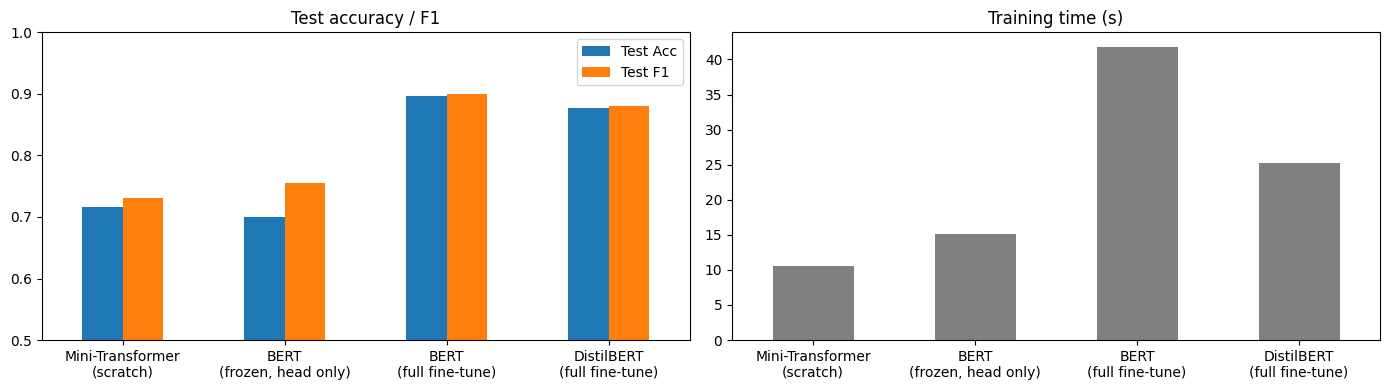

In [27]:
order = ["Mini-Transformer (scratch)", "BERT (frozen, head only)", "BERT (full fine-tune)", "DistilBERT (full fine-tune)"]
summary = pd.DataFrame({k: results[k] for k in order if k in results}).T

display(summary.style.format({"Params": "{:,}", "Trainable": "{:,}", "Test Acc": "{:.4f}", "Test F1": "{:.4f}",
                              "Train time (s)": "{:.1f}", "Test inference (s)": "{:.2f}"}))

# same table as Markdown, ready to paste into the cell above
print("| Model | Params | Trainable | Pre-trained | Test Acc | Test F1 | Train time |")
print("|---|---|---|---|---|---|---|")
for name, r in summary.iterrows():
    print(f"| {name} | {r['Params'] / 1e6:.1f}M | {r['Trainable']:,} | {r['Pre-trained']} | "
          f"{r['Test Acc']:.4f} | {r['Test F1']:.4f} | {r['Train time (s)']:.1f} s |")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
names = [n.replace(" (", "\n(") for n in summary.index]
summary[["Test Acc", "Test F1"]].astype(float).set_axis(names).plot.bar(ax=ax[0], rot=0, ylim=(0.5, 1.0))
ax[0].set_title("Test accuracy / F1")
summary["Train time (s)"].astype(float).set_axis(names).plot.bar(ax=ax[1], rot=0, color="gray")
ax[1].set_title("Training time (s)")
plt.tight_layout(); plt.show()

### Part 7 Answers

**1. Why does BERT beat the model trained from scratch?** Fully fine-tuned BERT reaches **0.897 accuracy vs 0.716** for the mini-Transformer (+18 points), although both are stacks of the same encoder block. The scratch model must learn *everything* from 5,000 labelled sentences: word meanings, word order, negation and sentiment. 94% of its parameters are an embedding table in which most rows belong to words seen once or never. It overfits quickly (train accuracy 0.87 vs validation 0.75), and Part 6 shows it only learned keyword-spotting heads. BERT starts from representations learned by MLM/NSP pre-training on ~3.3B words: it already knows that *awful* ≈ *terrible*, how *not* changes *bad*, and it has positional and syntactic heads. Fine-tuning only has to map this knowledge to two labels. That is why it handles negation and "but" contrasts in 5.5. Pre-training alone is not enough, though: **frozen** BERT (0.701) is no better than the scratch model. The gain comes from pre-training *plus* adapting the whole network.

**2. Why can't BERT translate directly?** Translation is conditional *generation*: the target is produced one token at a time, each token conditioned on the source and on the tokens already generated, and its length differs from the source. BERT is encoder-only:
* It has **no decoder with causal (masked) self-attention** and **no cross-attention** to a separate source sequence.
* It was **never trained to predict the next token**. MLM fills in blanks given context on *both* sides.
* Its attention is **bidirectional**, so every position sees the whole input including "future" tokens. That's ideal for understanding but makes left-to-right generation impossible without leaking the answer.
* It outputs exactly **one vector per input token**, so it cannot emit a sequence of a different length in another language.

Marian (Lab 9) adds an autoregressive decoder with cross-attention and is trained on parallel text. BERT could at most serve as the *encoder* of such a system.

**3. Why multiple heads instead of one big head?** One head produces one softmax distribution per token, so it can express only a single kind of relation at a time and would have to average several relations together. With *h* heads in *d_model/h*-dimensional subspaces, the **same parameter budget** (Part 3.2: 66,048 parameters for `d_model=128`, independent of *h*) buys *h* independent attention patterns, and `W_o` then combines them. Part 6 shows this specialisation directly:
* In **layer 1 alone**, head 4 looks at the previous token while head 11 looks at the next token.
* Elsewhere, layer 2 head 7 attends to `[CLS]` (86%), layer 6 head 2 to `[SEP]` (92%), and layer 12 head 8 to the clause-separating comma and period.
* Even the tiny mini-Transformer splits the work: its four block-1 heads each lock onto a different word (*acting*, *bad*, *was*, *not*).

A single head could not represent all of these relations at the same time.

**4. When to use each paradigm (Labs 8, 9, 10)?**
* **LSTM + attention (Lab 8):** small data and compute budgets, streaming input, or tiny on-device models trained from scratch where no suitable pre-trained model exists. It processes tokens sequentially, so it is slower to train and weaker than pre-trained Transformers, but it is a transparent baseline.
* **Pre-trained seq2seq Transformer (Lab 9, e.g. Marian / T5 / BART):** any *text-to-text generation* task where the output is a new sequence of different length: translation, summarisation, paraphrasing, generative QA. Fine-tune a pre-trained checkpoint on parallel data.
* **Pre-trained encoder (Lab 10, e.g. BERT / DistilBERT / RoBERTa):** *understanding* tasks whose output is a label per sentence or per token: sentiment/topic classification, NER/POS tagging, extractive QA, sentence embeddings for retrieval. It gives the best accuracy with few labels (0.897 from just 5,000 sentences here). Use DistilBERT when latency matters: −2 points for ~1.8x speed. Freezing the encoder is only worthwhile when compute is extremely limited.

## What to Submit
* The completed notebook with all outputs visible.
* The comparison table from Part 7 and your written answers.
* Screenshots (or outputs) of the attention heatmaps from Part 6.

**Bonus (+5):** Fine-tune a smaller model (`distilbert-base-uncased`) and add it to the table, commenting on the speed/accuracy trade-off.